# Holos-Quad RL Controller Validation Tutorial Notebook

Start by importing local scripts and veery

In [1]:
from veery.mcts import run_MCTS
from veery.fuzzing import DisturbanceDistribution
from veery.viz import plot_tree, plot_tree_structure
import profiles
import env
from helpers import load_trained_model
import disturbances

## Setting up the environment profile and disturbance models

First, let's get the testing profile we need to run a pre-trained model in the environment. 

In [2]:
_, testing_kwargs = profiles.get_profile(name="test", max_failed_drums=0)

Next, we need to load the model. 

In [3]:
model = load_trained_model("default")

Set up the disturbance distribution to sample noisy readings from.

In [4]:
disturbance_dist = DisturbanceDistribution(
    Do=disturbances.Do(
        sigma_p=0.01, # std of power noise distribution (Gaussian)
        sigma_drum=0.005 # std of drum angle noise distribution (Gaussian)
        ), 
    Da=disturbances.Da(sigma_dtheta=0.001), # std of rate of change of angle noise distribution (Gaussian)
    Ds=disturbances.Ds(
            sigma_nr=0, # std of neutron density noise distribution (Gaussian)
            sigma_precursors=0, # std of precursor noise distribution (Gaussian)
            sigma_Tf=0, # std of fuel temperature noise distribution (Gaussian)
            sigma_Tm=0, # std of moderator temp noise distribution (Gaussian)
            sigma_Tc=0, # std of coolant temp noise distribution (Gaussian)
            sigma_xe=0, # std of xenon concentration noise distribution (Gaussian)
            sigma_i=0 # std of iodine concentration noise distribution (Gaussian)
            )
    )

## Running Monte Carlo Tree Search

Now, we run the Monte Carlo Tree Search, from `veery`.

In [5]:
thresh = 0.03
environment = env.HolosMulti(**testing_kwargs)
tree = run_MCTS(
        environment=environment, 
        model=model,
        disturbance_dist=disturbance_dist, 
        results_path="results/notebook",
        threshold=thresh,
        iterations=100, 
        hyperparams=None
        )

100%|██████████| 100/100 [01:32<00:00,  1.08it/s]

Saved 2 failures to results/notebook


Now, plot the results!

(<Figure size 1000x1600 with 2 Axes>, <Axes: xlabel='Time, [s]'>)

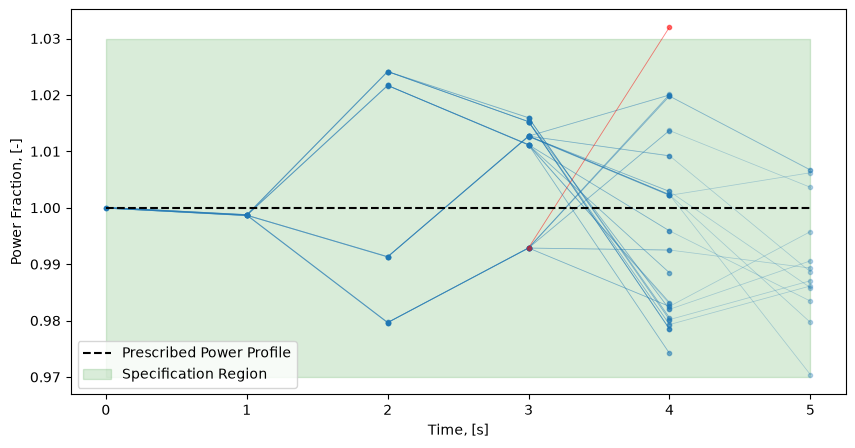

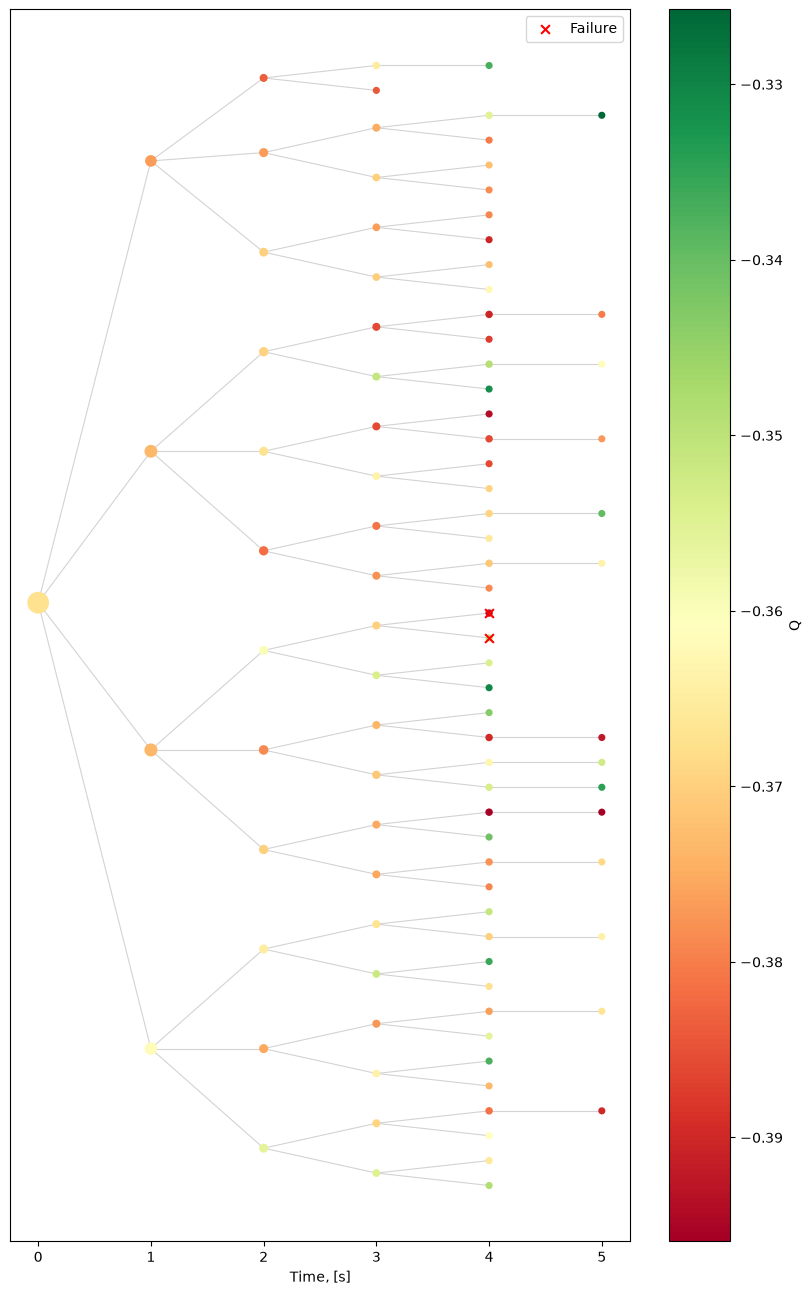

In [6]:
plot_tree(
        tree,
        spec_var="_p",
        profile=environment.profile,
        threshold=thresh,
        ylabel="Power Fraction, [-]",
        profile_label="Prescribed Power Profile",
        save_path="results/notebook/tree.png",
    )
plot_tree_structure(
        tree, save_path=f"results/notebook/tree_structure.png"
    )